# ACCTG 522: Enron email audit lab
Two 50-minute modules, with a 10-minute break. Design searches, evaluate evidence, and interpret findings using regular expressions. These are real, modified emails under hypothetical cybersecurity and employment policies. A match is a screening lead, never an established violation.

Keep the CSV private and unchanged. Do not commit it, upload it to external analysis services, or send it to an LLM. Colab requires an authorized upload to your own runtime; use VS Code locally if that is not permitted. Notebook excerpts are also data: clear outputs before sharing.

**Module 1 (50 minutes):** framing (5), one-email parsing (15), full-data checks (15), timing (15). **Break: 10 minutes. Module 2 (50 minutes):** search methods and PII (12), credentials (10), competitors (10), independent investigation (18). Extensions are optional.

## Instructor facilitation notes
All code and worked defaults follow the student sequence. Saved outputs provide actual dataset results after local execution. Ask for predictions before running each search, then distinguish observed counts from policy conclusions.

Suggested modifications: compare security/confidential; extend phone matches to extensions; add passcode to credentials; narrow employment language to interviews; revise the illustrative competitor list. Count changes are not automatically improvements. Encourage inspection of quoted text and signatures and discussion of both precision and missed evidence. Grade the independent investigation on a clear question, reproducible method, counted evidence, restrained interpretation, and limitations rather than the number of apparent violations.

Review the inspected examples at the end before class. They illustrate ambiguous screening results, not findings of misconduct. Avoid displaying plausible secrets or unnecessary personal information. Optional extensions are outside the core 100 minutes.

## 1. Load the data
In VS Code select a Python environment with pandas, matplotlib, and ipykernel. In Colab those analysis libraries are normally available. Place the CSV beside this notebook; the fallback upload dialog runs only in Colab. A proper CSV reader preserves quoted text and escaped quotation marks. We count records, not spreadsheet row labels.

In [1]:
from pathlib import Path
import re
from email.utils import parsedate_to_datetime
from datetime import timezone
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('Cybersecurity_case_studies_Enron.csv')
if not DATA.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Place {DATA.name} beside the notebook, or edit DATA.')
    files.upload()  # Upload only if your data-use permissions allow Colab.
df = pd.read_csv(DATA, dtype=str, keep_default_na=False, skip_blank_lines=False)
assert list(df.columns) == ['EmailData'], f'Unexpected columns: {list(df.columns)}'
df.insert(0, 'RecordID', range(1, len(df) + 1))  # CSV data-record number, excluding header
print(f'{len(df):,} records; {len(df.columns)-1} original column')
print('Empty/whitespace records:', df.EmailData.str.strip().eq('').sum())

26,751 records; 1 original column
Empty/whitespace records: 0


## 2. Transform one email first
Inspect one record before applying transformations. The outer labels follow Message-ID, Date, From, To, Subject. Split at the first outer `Subject:` label and retain every character: EmailHeader + EmailBody must reconstruct the original. Under this case convention EmailBody includes the subject. Flattening does not reliably preserve the boundary between subject and newly written text.

In [2]:
example = df.loc[df.EmailData.str.strip().ne(''), 'EmailData'].iloc[0]
print(example)  # The only full email displayed in this notebook.

def split_email(text):
    # First Subject label, after the outer To label; keep the label in the body.
    m = re.match(r'\AMessage-ID:.*?\sDate:.*?\sFrom:.*?\sTo:.*?\s(?=Subject:)', text, re.S)
    return (text[:m.end()], text[m.end():]) if m else ('', '')

header, body = split_email(example)
print('Header:', header)
print('Body starts:', body[:160])
assert header + body == example

# Anchoring to the whole header prevents forwarded labels in the body from being used.
OUTER = re.compile(r'\AMessage-ID:\s*(?P<MessageID><[^>]+>)\s+Date:\s*(?P<DateRaw>.*?)\s+From:\s*(?P<FromRaw>.*?)\s+To:\s*(?P<ToRaw>.*?)\s*\Z', re.S)
print(OUTER.fullmatch(header).groupdict())

Message-ID: <25828831.1075855376669.JavaMail.evans@thyme> Date: Mon, 26 Nov 2001 07:25:16 -0800 (PST) From: k..allen@enron.com To: jsmith@austintx.com Subject: RE: Additional properties in San Antonio Jeff, Can you resend the info on the three properties you mailed and the one you faxed on Tuesday. I was out of the office last week. Phillip -----Original Message----- From: "JEFF SMITH" <jsmith@austintx.com>@ENRON Sent: Tuesday, November 20, 2001 3:43 PM To: Allen, Phillip K. Subject: Additional properties in San Antonio Phillip, I am waiting to get info. on two more properties in San Antonio. The broker will be faxing info. on Monday. One is 74 units for $1,900,000, and the other is 24 units for $550,000. Also, I have mailed you info. on three other properties in addition to the 100 unit property that I faxed this AM. Let me know if you have any questions. Jeff Smith The Smith Company 9400 Circle Drive Austin, TX 78736 512-394-0908 office 512-394-0913 fax 512-751-9728 mobile jsmith@aus

`.*?` captures as little text as needed until the next ordered label. Named groups retain raw metadata. Address extraction keeps the supplied spelling, including leading dots. A conservative format check flags unusual strings for review; it never repairs them. Multiple recipients remain a semicolon-separated list of extracted addresses.

In [3]:
ADDRESS = re.compile(r'[^\s<>;,]+@[^\s<>;,]+')
EXPECTED = re.compile(r'[A-Za-z0-9_+%-]+(?:\.[A-Za-z0-9_+%-]+)*@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+')
def addresses(raw):
    return '; '.join(ADDRESS.findall(raw))
def unexpected(raw):
    found = ADDRESS.findall(raw)
    return not found or any(EXPECTED.fullmatch(a) is None for a in found)

parts = df.EmailData.map(split_email)
df['EmailHeader'] = [p[0] for p in parts]
df['EmailBody'] = [p[1] for p in parts]
metadata = df.EmailHeader.map(lambda h: OUTER.fullmatch(h))
for field in ['MessageID', 'DateRaw', 'FromRaw', 'ToRaw']:
    df[field] = metadata.map(lambda m: m.group(field) if m else '')
for side in ['From', 'To']:
    df[side+'Email'] = df[side+'Raw'].map(addresses)
    df[side+'FormatFlag'] = df[side+'Raw'].map(unexpected)
split_ok = df.EmailBody.str.startswith('Subject:')
assert (df.loc[split_ok, 'EmailHeader'] + df.loc[split_ok, 'EmailBody']).equals(df.loc[split_ok, 'EmailData'])
quality = pd.DataFrame({
    'nonempty_count': df[['MessageID','EmailHeader','EmailBody','DateRaw','FromRaw','ToRaw','FromEmail','ToEmail']].ne('').sum()
})
quality['percent'] = (100 * quality.nonempty_count / len(df)).round(2)
display(quality)
duplicate = df.MessageID.ne('') & df.MessageID.duplicated(keep=False)
print('Unsplit:', (~split_ok).sum(), '| metadata failures:', metadata.isna().sum())
print('Records in duplicate-ID groups:', duplicate.sum(), '| excess copies:', df.loc[df.MessageID.ne(''), 'MessageID'].duplicated().sum())
print('Address-format flags:', df[['FromFormatFlag','ToFormatFlag']].sum().to_dict())
print('No records were deleted.')

,nonempty_count,percent
MessageID,26751,100.0
EmailHeader,26751,100.0
EmailBody,26751,100.0
DateRaw,26751,100.0
FromRaw,26751,100.0
ToRaw,26751,100.0
FromEmail,26751,100.0
ToEmail,26751,100.0


Unsplit: 0 | metadata failures: 0
Records in duplicate-ID groups: 0 | excess copies: 0
Address-format flags: {'FromFormatFlag': 5711, 'ToFormatFlag': 1885}
No records were deleted.


## 3. Recorded local time and UTC
The standard-library email date parser understands numeric offsets and parenthesized zone labels. Failures and missing offsets remain explicit. Store local components directly from each parsed timestamp before converting to UTC. Mixed offsets must not be treated as one local timezone.

**Predict:** Which weekday and hour will dominate? Recorded local time does not establish physical location, employment status, or working schedule.

Date failures: 0
Recorded local date coverage: 2000-11-01 to 2002-06-25
UTC coverage: 2000-11-01 19:29:00+00:00 to 2002-06-25 14:51:14+00:00


,RecordID,DateRaw


,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Emails,5837,5872,5404,4822,4066,243,507


LocalHour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Emails,37,22,29,42,276,1016,1876,2489,2646,2412,...,2203,1660,951,522,469,315,215,96,42,23


,2000-11,2000-12,2001-01,2001-02,2001-03,2001-04,2001-05,2001-06,2001-07,2001-08,2001-09,2001-10,2001-11,2001-12,2002-01,2002-02,2002-03,2002-04,2002-05,2002-06
Emails,59,103,79,112,304,1100,1937,1328,1386,2017,2153,5483,4391,1757,2289,1112,641,243,121,136


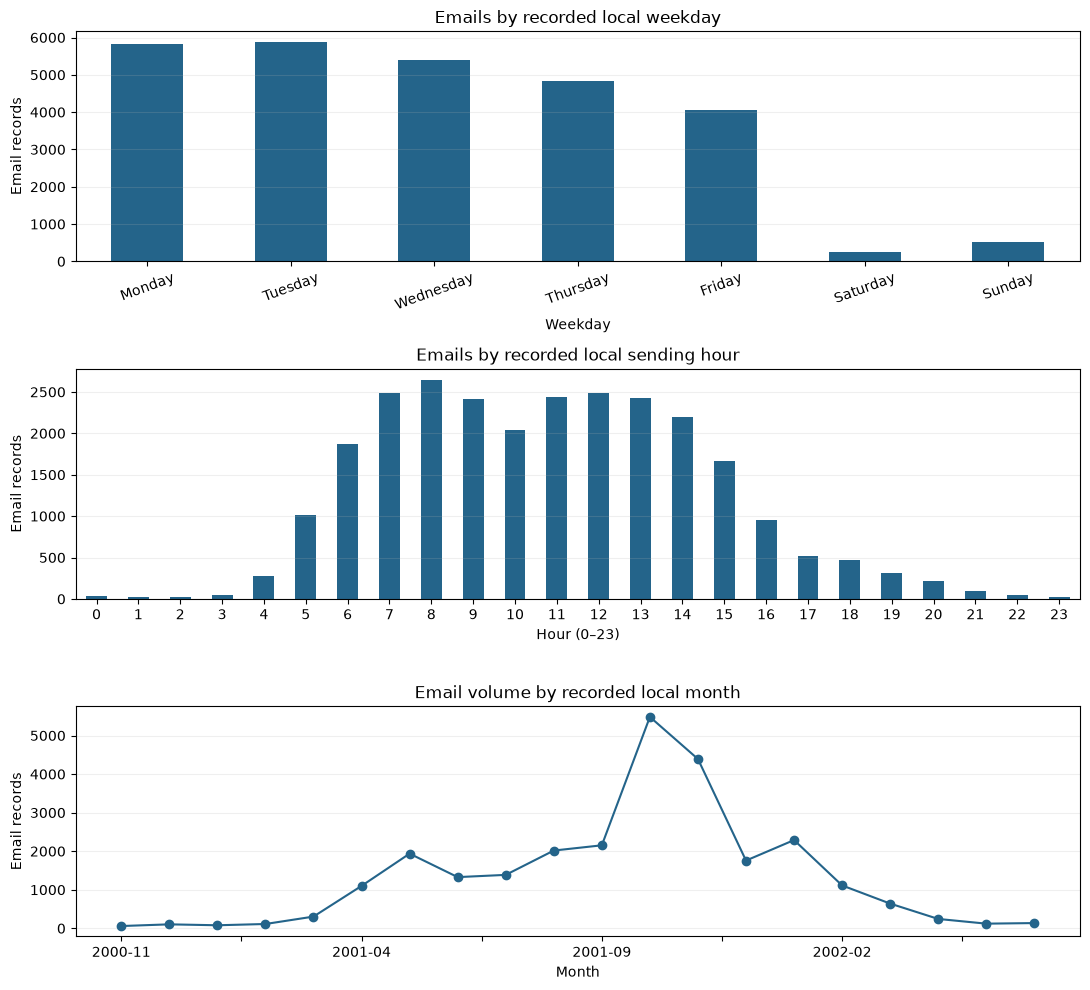

In [4]:
def parse_date(raw):
    try:
        dt = parsedate_to_datetime(raw)
        if dt.tzinfo is None or dt.utcoffset() is None:
            return None
        return dt
    except (ValueError, TypeError, OverflowError):
        return None

dates = [parse_date(s) for s in df.DateRaw]
df['LocalDate'] = [d.date() if d else None for d in dates]
df['LocalWeekday'] = [d.weekday() if d else None for d in dates]
df['LocalHour'] = [d.hour if d else None for d in dates]
df['TimestampUTC'] = pd.to_datetime([d.astimezone(timezone.utc) if d else None for d in dates], utc=True)
print('Date failures:', sum(d is None for d in dates))
print('Recorded local date coverage:', df.LocalDate.dropna().min(), 'to', df.LocalDate.dropna().max())
print('UTC coverage:', df.TimestampUTC.min(), 'to', df.TimestampUTC.max())
display(df.loc[df.TimestampUTC.isna(), ['RecordID','DateRaw']].head(5))
weekday = df.LocalWeekday.value_counts().reindex(range(7), fill_value=0)
weekday.index = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
hour = df.LocalHour.value_counts().reindex(range(24), fill_value=0)
monthly = pd.Series([str(d)[:7] for d in df.LocalDate if d is not None]).value_counts().sort_index()
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq='M').astype(str), fill_value=0)
display(weekday.rename('Emails').to_frame().T)
display(hour.rename('Emails').to_frame().T)
display(monthly.rename('Emails').to_frame().T)
fig, axes = plt.subplots(3, 1, figsize=(11, 10))
weekday.plot.bar(ax=axes[0], color='#24648a', rot=20, title='Emails by recorded local weekday')
hour.plot.bar(ax=axes[1], color='#24648a', rot=0, title='Emails by recorded local sending hour')
monthly.plot(ax=axes[2], marker='o', color='#24648a', title='Email volume by recorded local month')
for ax in axes:
    ax.set_ylabel('Email records'); ax.grid(axis='y', alpha=.2)
axes[0].set_xlabel('Weekday'); axes[1].set_xlabel('Hour (0–23)'); axes[2].set_xlabel('Month')
plt.tight_layout(); plt.show()

**Try it:** Change the monthly summary to yearly using `str(d)[:4]` in a new cell. Interpret a peak and a gap. Are apparent changes explained by coverage or sender composition? Do not infer business activity from this sample alone.

## 4. Validate boundary cases
Synthetic records check quoted metadata, display names, unusual addresses, mixed offsets, and match counts without needing additional real emails.

In [5]:
synthetic = 'Message-ID: <test> Date: Wed, 11 Jul 2001 08:25:40 -0700 (PDT) From: legal <.taylor@enron.com> To: a@example.com Subject: Hi -----Original Message----- Date: yesterday From: wrong@example.com To: other@example.com Subject: quoted'
sh, sb = split_email(synthetic)
sm = OUTER.fullmatch(sh).groupdict()
assert sh + sb == synthetic and sb.startswith('Subject: Hi')
assert sm['FromRaw'] == 'legal <.taylor@enron.com>'
assert addresses(sm['FromRaw']) == '.taylor@enron.com' and unexpected(sm['FromRaw'])
assert sm['ToRaw'] == 'a@example.com'
assert split_email('malformed') == ('', '')
d1 = parse_date('Mon, 26 Nov 2001 07:25:16 -0800 (PST)')
d2 = parse_date(sm['DateRaw'])
assert (d1.hour, d1.astimezone(timezone.utc).hour) == (7, 15)
assert (d2.hour, d2.astimezone(timezone.utc).hour) == (8, 15)
assert parse_date('bad') is None
print('Synthetic metadata and date checks passed.')

Synthetic metadata and date checks passed.


## 5. Search helper and worked keyword search
By default search the complete EmailBody, including the subject and quoted threads, for comparability with the earlier Alteryx case. Return one row per matching record. Occurrences are non-overlapping regex matches and can exceed the number of matching records. The excerpt surrounds the first match; read other occurrences before deciding what the record supports.

In [6]:
def search(pattern, scope='EmailBody', frame=None):
    frame = df if frame is None else frame
    rx = re.compile(pattern, re.I)
    rows = []
    for _, r in frame.iterrows():
        text = r[scope]
        hits = list(rx.finditer(text))
        if hits:
            a, b = hits[0].span()
            rows.append({'RecordID':r.RecordID, 'MessageID':r.MessageID,
                         'Sender':r.FromEmail, 'Recipient':r.ToEmail, 'Date':r.DateRaw,
                         'MatchCount':len(hits), 'Excerpt':text[max(0,a-80):b+100]})
    return pd.DataFrame(rows, columns=['RecordID','MessageID','Sender','Recipient','Date','MatchCount','Excerpt'])

def report(result, n=3):
    print(f'Matching email records: {len(result):,}; total occurrences: {int(result.MatchCount.sum()):,}')
    display(result[['RecordID','Sender','Date','MatchCount','Excerpt']].head(n))

keyword = r'\bsecurity\b'  # Word boundaries avoid matching a word fragment.
keyword_hits = search(keyword)
report(keyword_hits)
toy = df.head(1).copy(); toy['EmailBody'] = 'password PASSWORD passwordless'
test_hits = search(r'\bpassword\b', frame=toy)
assert len(test_hits) == 1 and test_hits.MatchCount.iloc[0] == 2
print('Record versus occurrence check passed.')

Matching email records: 357; total occurrences: 838


,RecordID,Sender,Date,MatchCount,Excerpt
0,146,k..allen@enron.com,"Wed, 12 Sep 2001 06:17:02 -0700 (PDT)",5,"s, nuclear fuel facilities and gaseous diffusi..."
1,191,k..allen@enron.com,"Thu, 25 Oct 2001 13:41:56 -0700 (PDT)",1,that the account balance will be treated as o...
2,192,k..allen@enron.com,"Thu, 25 Oct 2001 14:32:32 -0700 (PDT)",2,":05 PM To: Allen, Phillip K. Subject: RE: Dist..."


Record versus occurrence check passed.


**Try it:** Replace `security` with `confidential`, predict how results change, and inspect three excerpts. Explain one false positive and one way your search might miss a relevant record.

## 6. Worked structured pattern: phone numbers and PII
The original PII policy was not supplied. Phone numbers are an illustrative teaching category. This pattern detects common North American forms; an ordinary business signature may match. Sensitivity depends on policy, ownership, and context. It misses international formats, obfuscated digits, and some extensions.

In [7]:
phone_pattern = r'(?<!\w)(?:\+?1[ .-]?)?(?:\(\d{3}\)|\d{3})[ .-]\d{3}[ .-]\d{4}(?!\d)'
# Three-digit area code, separator, three digits, separator, four digits.
phone_hits = search(phone_pattern)
report(phone_hits)

Matching email records: 6,668; total occurrences: 14,947


,RecordID,Sender,Date,MatchCount,Excerpt
0,1,k..allen@enron.com,"Mon, 26 Nov 2001 07:25:16 -0800 (PST)",3,any questions. Jeff Smith The Smith Company 9...
1,2,k..allen@enron.com,"Sun, 2 Dec 2001 18:45:38 -0800 (PST)",1,tracts) for less than 1 month trades. Please c...
2,7,k..allen@enron.com,"Wed, 13 Jun 2001 13:01:19 -0700 (PDT)",4,orizes the transfer. If it is acceptable pleas...


**Try it:** Add an optional extension with `(?:\s*(?:ext\.?|x)\s*\d{1,5})?`. Does it change matching records, occurrences, or only the matched span? Review a signature and a nonsignature example if available. Propose another illustrative PII category and explain its risks before searching. These results are not a census of sensitive information.

## 7. Possible password/login sharing
Compare references to credentials with disclosure candidates. Neither pattern proves disclosure: a placeholder, instructions, quoted text, or a warning can match. Actual disclosures may omit the words password/login, use unusual spacing, or refer to unavailable attachments.

In [8]:
credential_reference = r'\b(?:passwords?|logins?|usernames?)\b'
credential_candidate = r'\b(?:password|login|username)\s*(?:is\b|:|=)\s*\S+'
credential_hits = search(credential_reference)
candidate_hits = search(credential_candidate)
report(credential_hits)
report(candidate_hits)

def inspect_record(record_id, pattern, radius=140, max_hits=4):
    text = df.loc[df.RecordID.eq(record_id), 'EmailBody'].iloc[0]
    for i, match in enumerate(re.finditer(pattern, text, re.I)):
        if i >= max_hits: break
        print(repr(text[max(0, match.start()-radius):match.end()+radius]))

if not candidate_hits.empty:
    inspect_record(int(candidate_hits.iloc[0].RecordID), credential_candidate)

Matching email records: 391; total occurrences: 880


,RecordID,Sender,Date,MatchCount,Excerpt
0,53,k..allen@enron.com,"Tue, 17 Jul 2001 05:36:39 -0700 (PDT)",2,all: simtrader2 access to us gas only: simtrad...
1,54,k..allen@enron.com,"Tue, 17 Jul 2001 07:47:41 -0700 (PDT)",2,all: simtrader2 access to us gas only: simtrad...
2,57,k..allen@enron.com,"Tue, 17 Jul 2001 13:33:50 -0700 (PDT)",2,all: simtrader2 access to us gas only: simtrad...


Matching email records: 94; total occurrences: 131


,RecordID,Sender,Date,MatchCount,Excerpt
0,53,k..allen@enron.com,"Tue, 17 Jul 2001 05:36:39 -0700 (PDT)",1,all: simtrader2 access to us gas only: simtrad...
1,54,k..allen@enron.com,"Tue, 17 Jul 2001 07:47:41 -0700 (PDT)",1,all: simtrader2 access to us gas only: simtrad...
2,57,k..allen@enron.com,"Tue, 17 Jul 2001 13:33:50 -0700 (PDT)",1,all: simtrader2 access to us gas only: simtrad...


"y: simtrader3, simtrader4 Phillip's accounts are: access to all: simtrader2 access to us gas only: simtrader5, simtrader6 In each case, the password is the same as the username. Let me know if you have any questions. Thanks! --jay"


**Try it:** Add `passcode` to both patterns. Inspect surrounding text and distinguish a reference, a candidate disclosure, and an unresolved match. Attribute quoted statements cautiously: the outer sender may only be forwarding another person's words. Do not reproduce plausible credentials in reports.

## 8. Hypothetical competitor-interview policy
Assume, for discussion only, a policy against interviewing with competitors. The original policy and competitor list were not supplied. The editable names below are illustrative teaching assumptions, not an authoritative list. A job, recruiter, or employer mention does not establish an interview or violation. AND screening requires co-occurrence in the same email, which may span unrelated quoted messages.

In [9]:
employment_pattern = r'\b(?:interview\w*|recruit\w*|resume|job opportunit\w*|employment)\b'
competitors = ['Dynegy', 'Duke Energy', 'Reliant']  # Illustrative, editable assumptions.
competitor_pattern = r'\b(?:' + '|'.join(re.escape(name) for name in competitors) + r')\b'
broad_hits = search(employment_pattern)
name_hits = search(competitor_pattern)
narrow_hits = broad_hits[broad_hits.RecordID.isin(name_hits.RecordID)].copy()
print('Broad employment screening:'); report(broad_hits)
print('Employment AND illustrative competitor screening:'); report(narrow_hits)
# MatchCount in this table counts employment-language occurrences, not name occurrences.
if not narrow_hits.empty:
    inspect_record(int(narrow_hits.iloc[0].RecordID), competitor_pattern)

Broad employment screening:
Matching email records: 1,273; total occurrences: 2,864


,RecordID,Sender,Date,MatchCount,Excerpt
0,5,k..allen@enron.com,"Thu, 7 Jun 2001 13:54:09 -0700 (PDT)",2,"Subject: Greg, I typed up this resume from scr..."
1,146,k..allen@enron.com,"Wed, 12 Sep 2001 06:17:02 -0700 (PDT)",2,"itzgerald, Mizuho Holdings, Bank of America, A..."
2,197,k..allen@enron.com,"Mon, 29 Oct 2001 08:07:57 -0800 (PST)",4,E: the candidate we spoke about this morning.....


Employment AND illustrative competitor screening:
Matching email records: 69; total occurrences: 177


,RecordID,Sender,Date,MatchCount,Excerpt
15,348,john.arnold@enron.com,"Wed, 23 May 2001 08:42:00 -0700 (PDT)",1,"sion Corp (KPTCL), the state's monopoly power ..."
36,789,john.arnold@enron.com,"Thu, 25 Oct 2001 12:53:01 -0700 (PDT)",1,jobless claims expected by economists. The La...
41,897,john.arnold@enron.com,"Wed, 7 Nov 2001 14:14:30 -0800 (PST)",5,"ys Late (Update2) Bloomberg, 11/07/01 Former S..."


"Enron, Calpine Corp= ., the nation's leading independent-power company, based in California, wil= l move into a new 32-story high-rise. And Reliant Resources, the IPO spun o= ff this month from its Houston parent to deal with Texas' new deregulated e= lectricity market, has signed on fo"
'go, there = were no trading floors," points out Stephen Brown, senior economist with th= e Federal Reserve Bank in Dallas. Both Calpine and Reliant will also have t= rading operations in their new offices. Though Houston no longer relies so= heavily on the energy business (down to 48% o'


**Try it:** Edit the names and compare `interview\w*` alone with the broader employment pattern. Review both kinds of excerpts. Could the discussion concern hiring somebody else? What evidence would be needed to establish who interviewed, when, and under which policy?

## 9. Independent investigation
“Propose a question that can be investigated using this email dataset. Explain why the question matters and describe your search method. Review matching emails and report your findings, supported by counts and selected examples. Identify at least one limitation of your method, including possible false positives or missed matches.”

**Response template:** Question → Rationale → Search method → Evidence → Interpretation → Limitation.

Report the scope and pattern, matching records and occurrences, selected RecordIDs with short redacted excerpts, and how many matches you reviewed. Separate observed text from inference. Include at least one possible false positive or missed match.

In [10]:
# Try it: replace this worked default with your investigation pattern.
investigation_pattern = r'\bconfidential\b'
investigation_hits = search(investigation_pattern)
report(investigation_hits)

Matching email records: 2,309; total occurrences: 3,039


,RecordID,Sender,Date,MatchCount,Excerpt
0,17,k..allen@enron.com,"Wed, 20 Jun 2001 07:42:29 -0700 (PDT)",1,ch the deal was entered into the type of trade...
1,18,k..allen@enron.com,"Wed, 20 Jun 2001 08:09:31 -0700 (PDT)",4,to Discuss Possible Options to Mitigate Effect...
2,27,k..allen@enron.com,"Mon, 25 Jun 2001 13:48:13 -0700 (PDT)",2,Subject: RE: Western Wholesale Activities - Ga...


## Optional extension A: quoted threads, artifacts, and attachments
Text before the first recognized delimiter is a heuristic and still includes the subject. It cannot universally isolate newly authored text. Compare search scope rather than assuming quoted text is irrelevant.

Artifacts such as `=09`, `=20`, and `= ` inside split words can cause missed matches. Preserve EmailData and do not decode all text as quoted-printable or strip equals signs. The optional experiment below replaces only two explicit tokens in a separate field; it may alter legitimate text and does not repair split words reliably.

`<< File: ... >>` is an attachment reference. The CSV does not thereby contain the attachment, and these notebooks do not inspect its contents.

In [11]:
thread_delimiter = r'-{2,}\s*Original Message\s*-{2,}|-{2,}\s*Forwarded by\b'
df['BeforeThreadHeuristic'] = df.EmailBody.map(lambda t: re.split(thread_delimiter, t, maxsplit=1, flags=re.I)[0])
print('Full body:'); report(search(credential_reference), n=0)
print('Before delimiter heuristic:'); report(search(credential_reference, 'BeforeThreadHeuristic'), n=0)
RUN_CLEANING_EXPERIMENT = False  # Try it: enable and compare, preserving the original.
if RUN_CLEANING_EXPERIMENT:
    df['ExperimentalBody'] = df.EmailBody.str.replace('=09', ' ', regex=False).str.replace('=20', ' ', regex=False)
    report(search(credential_reference, 'ExperimentalBody'), n=0)
attachment_hits = search(r'<<\s*File:.*?>>')
print('Records with attachment references:', len(attachment_hits))

Full body:


Matching email records: 391; total occurrences: 880


,RecordID,Sender,Date,MatchCount,Excerpt


Before delimiter heuristic:


Matching email records: 147; total occurrences: 217


,RecordID,Sender,Date,MatchCount,Excerpt


Records with attachment references: 2305


## Optional extension B: language indicators over time
These transparent dictionaries measure selected words, not validated sentiment or emotional state. Do not assume tone deteriorated. Monthly proportions use all dated email records as the denominator and count each category at most once per email. Display sample sizes alongside proportions. Changing sender composition, quoted text, incomplete coverage, negation, and word meanings limit interpretation. No causal claims or scandal event dates are supplied.

,Emails,Concern,Uncertainty,Reassurance,Concern proportion,Uncertainty proportion,Reassurance proportion
Month,,,,,,,
2000-11,59,1,1,0,0.017,0.017,0.000
2000-12,103,9,2,0,0.087,0.019,0.000
2001-01,79,6,1,0,0.076,0.013,0.000
2001-02,112,15,4,0,0.134,0.036,0.000
2001-03,304,34,25,2,0.112,0.082,0.007
2001-04,1100,94,42,12,0.085,0.038,0.011
2001-05,1937,167,116,18,0.086,0.060,0.009
2001-06,1328,135,67,6,0.102,0.050,0.005
2001-07,1386,151,79,7,0.109,0.057,0.005


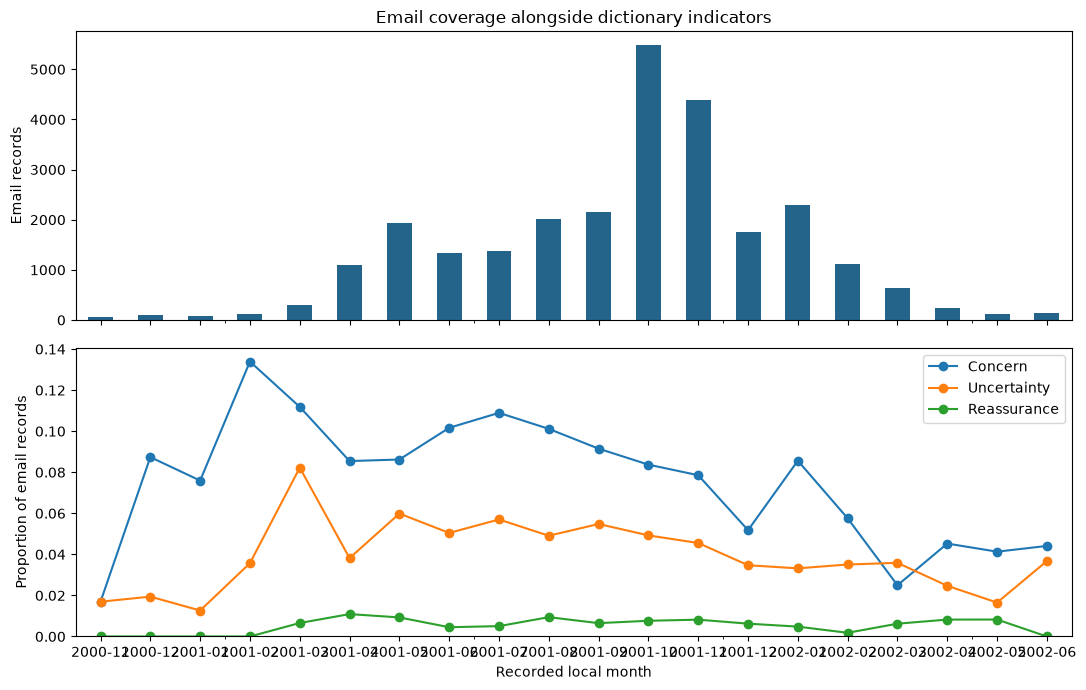

Try it: change one dictionary term and explain the sensitivity of the result.


In [12]:
language = {'Concern': ['concern', 'risk', 'problem'],
            'Uncertainty': ['perhaps', 'uncertain', 'maybe'],
            'Reassurance': ['confident', 'assure', 'reassure']}
language_data = pd.DataFrame({'Month': [str(d)[:7] if d else None for d in df.LocalDate]})
for category, words in language.items():
    pattern = r'\b(?:' + '|'.join(re.escape(w) for w in words) + r')\b'
    language_data[category] = df.EmailBody.str.contains(pattern, case=False, regex=True)
language_summary = language_data.dropna(subset=['Month']).groupby('Month').agg(
    Emails=('Concern','size'), **{c:(c,'sum') for c in language})
proportions = language_summary[list(language)].div(language_summary.Emails, axis=0)
display(language_summary.assign(**{c+' proportion':proportions[c].round(3) for c in language}))
fig, axes = plt.subplots(2, 1, figsize=(11,7), sharex=True)
language_summary.Emails.plot.bar(ax=axes[0], color='#24648a', title='Email coverage alongside dictionary indicators')
axes[0].set_ylabel('Email records')
proportions.plot(ax=axes[1], marker='o'); axes[1].set_ylabel('Proportion of email records')
axes[1].set_ylim(bottom=0); axes[1].set_xlabel('Recorded local month')
plt.tight_layout(); plt.show()
print('Try it: change one dictionary term and explain the sensitivity of the result.')

## Instructor: inspected ambiguous examples and measured results

These examples were selected after reviewing the supplied text. RecordID is the one-based CSV data-record number; it excludes the header. Short descriptions below avoid reproducing credentials or unnecessary contact details.

| RecordID | Observed context | Discussion |
|---|---|---|
| 1 | Phone hits appear in a business signature with office, fax, and mobile labels. | A phone-shaped string is not automatically prohibited PII. The hypothetical policy must define scope. |
| 2 | A phone number occurs with a signature before an Original Message delimiter. | Full-body counts may include both current and quoted material. Inspect provenance before attributing a statement. |
| 53 | Simulation-access instructions relate a password to a username. | This is stronger evidence of sharing access information than a mere password mention, but the text alone does not establish authorization, account status, or a policy violation. Avoid displaying the account identifiers. |
| 2508 | Online registration instructions describe a shared initial credential and a first-time registration process. | A candidate disclosure may be an intended onboarding mechanism; intent and policy remain unresolved. |
| 7454 | A file password is described in relation to the filename to prevent accidental edits. | Protection from accidental changes is different from access control for confidential data; the attachment itself is not available for inspection. |
| 24989 | The subject concerns trading-assistant interviews and arranging a meeting. | Broad interview language can concern hiring activity, rather than an employee interviewing with a competitor. |

On this supplied CSV: **26,751 records and one original column; no empty records, split failures, outer metadata failures, date failures, or duplicate MessageIDs.** All successful splits reconstruct the original exactly. Recorded local dates span **2000-11-01 through 2002-06-25**; UTC coverage is **2000-11-01 19:29:00+00:00 through 2002-06-25 14:51:14+00:00**. The conservative address checker flags **5,711 sender records and 1,885 recipient records**; these are format-review flags, not repaired addresses or proof of invalid delivery.

| Default search | Matching records | Occurrences |
|---|---:|---:|
| security | 357 | 838 |
| phone pattern | 6,668 | 14,947 |
| credential reference | 391 | 880 |
| credential candidate | 94 | 131 |
| broad employment | 1,273 | 2,864 |
| employment AND illustrative names | 69 | 177 employment matches |
| confidential investigation default | 2,309 | 3,039 |

The before-thread heuristic reduces credential-reference matching to 147 records and 217 occurrences. That comparison measures scope sensitivity, not improved accuracy. A quoted match can still matter, while a delimiter can fail to identify an entire thread.

Instructor review before teaching: decide the hypothetical policy definitions and competitor assumptions; review excerpt suitability and redact any secrets; distinguish ambiguous leads from conclusions; confirm authorization for Colab uploads. Neither email coverage nor these regex dictionaries supports causal claims about misconduct or emotional state.